# 02 - Baseline: TF-IDF + Logistic Regression
AG News, 4 classes: World, Sports, Business, Sci/Tech.
Notebook chạy từ thư mục `notebooks/`; logic nằm trong `src/baseline.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src import baseline

## 1. Train, chọn C trên validation, đánh giá trên test

In [2]:
metrics = baseline.run()

C=0.25  val macro-F1=0.9161  fit time=11.4s
C=0.5   val macro-F1=0.9210  fit time=11.6s
C=1.0   val macro-F1=0.9228  fit time=11.1s
C=2.0   val macro-F1=0.9243  fit time=11.7s
C=5.0   val macro-F1=0.9230  fit time=14.5s

=== Baseline (test set) ===
model                     baseline
accuracy                  0.919605
precision_macro           0.919489
recall_macro              0.919605
f1_macro                  0.919449
train_time_s             11.716433
inference_time_s          0.238444
inference_ms_per_sample   0.031374
trainable_params            200004
model_size_mb             3.408733
best_val_f1_macro         0.924311
best_C                         2.0
n_train                     108000
n_val                        12000
n_test                        7600
seed                            42
device                         cpu

Confusion matrix (rows = true, cols = predicted):
[[1727   56   70   47]
 [  20 1861   13    6]
 [  58   16 1679  147]
 [  42   16  120 1722]]

           

## 2. Metrics đã lưu 

In [3]:
pd.read_csv(baseline.METRICS_PATH)

,model,accuracy,precision_macro,recall_macro,f1_macro,train_time_s,inference_time_s,inference_ms_per_sample,trainable_params,model_size_mb,best_val_f1_macro,best_C,n_train,n_val,n_test,seed,device
0,baseline,0.919605,0.919489,0.919605,0.919449,11.716433,0.238444,0.031374,200004,3.408733,0.924311,2.0,108000,12000,7600,42,cpu


## 3. Confusion matrix

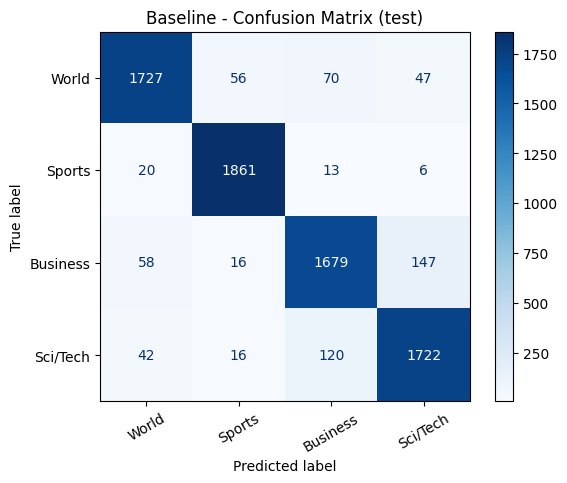

In [4]:
pred = pd.read_csv(baseline.PREDICTIONS_PATH)
cm = confusion_matrix(pred["true_label"], pred["pred_label"])
ConfusionMatrixDisplay(cm, display_labels=baseline.LABEL_NAMES).plot(cmap="Blues", xticks_rotation=30)
plt.title("Baseline - Confusion Matrix (test)")
plt.show()

## 4. Xem nhanh các mẫu dự đoán sai (tự tin cao nhất)

In [5]:
pred = pd.read_csv(baseline.PREDICTIONS_PATH)
wrong = pred[~pred["correct"]].sort_values("confidence", ascending=False)
print(f"Sai {len(wrong)} / {len(pred)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 611 / 7600 mẫu


,text,true_name,pred_name,confidence
2591,Sports Court Hears Hamm Gold Medal Appeal LAUS...,World,Sports,0.996656
5129,Product Previews palmOneUpgrades Treo With Fas...,Business,Sci/Tech,0.995795
6592,"Sony, IBM, Toshiba Give Details of 'Cell' Chip...",Business,Sci/Tech,0.994617
5128,Argentina Basketball Coach Magnano Quits Ruben...,World,Sports,0.994266
3617,Linux: Paris weighs a shift to open-source cam...,Business,Sci/Tech,0.994176
4097,"Greenspan: Debt, home prices not dangerous The...",Sci/Tech,Business,0.994093
7539,Mars water tops science honours The discovery ...,World,Sci/Tech,0.992747
3856,September Retail Sales Up by 1.5 Percent WASHI...,World,Business,0.992583
747,Argentina Beats U.S. Men's Basketball Team Arg...,World,Sports,0.992217
5740,Dow Jones Agrees to Buy MarketWatch in $519 Mi...,World,Business,0.992058
